<a href="https://colab.research.google.com/github/faiz-al123/EDA-dan-Reprosessing-/blob/main/UAS_Eda_dan_Preprocessing_data_Students_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas EDA dan Preprocessing Data Matakuliah Machine Learning.
Nama anggota kelompok:


*   Ahmad aly 2488010069
*   Faiz alfaresi 2488010012


*   Nazwa hummaimah 24880100

Sel 1 — Import Library

In [1]:
# Manipulasi dan analisis data
import pandas as pd
import numpy as np

# Visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Menghilangkan warning
import warnings
warnings.filterwarnings('ignore')

print("Library berhasil diimport!")

Library berhasil diimport!


Sel 2 — Upload Dataset

In [2]:
from google.colab import files
import pandas as pd

# Upload dataset
uploaded = files.upload()

# Mengambil nama file yang diupload secara otomatis
file_name = next(iter(uploaded))

# Membaca file berdasarkan formatnya dengan penanganan fallback jika format tidak sesuai
try:
    if file_name.endswith('.csv'):
        df = pd.read_csv(file_name)
    elif file_name.endswith(('.xls', '.xlsx')):
        try:
            df = pd.read_excel(file_name)
        except Exception as e:
            # Jika gagal membaca sebagai Excel, coba baca sebagai CSV
            print("Gagal membaca sebagai Excel, mencoba membaca sebagai CSV...")
            df = pd.read_csv(file_name)
    else:
        # Mencoba membaca langsung jika ekstensi tidak dikenal
        df = pd.read_csv(file_name)

    print("\nDataset berhasil dimuat!")
    print("Nama file:", file_name)
    print("Ukuran dataset:", df.shape)
    display(df.head())
except Exception as e:
    print(f"Gagal memuat dataset: {e}")

Saving StudentsPerformance.xls to StudentsPerformance.xls
Gagal membaca sebagai Excel, mencoba membaca sebagai CSV...

Dataset berhasil dimuat!
Nama file: StudentsPerformance.xls
Ukuran dataset: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Sel 3 — Menampilkan Data

In [3]:
# Menampilkan 5 data pertama
display(df.head())

# Menampilkan 5 data terakhir
display(df.tail())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


Sel 4 — Informasi Dataset

In [4]:
# Informasi dataset
print("Informasi Dataset:")
df.info()

print("\nUkuran Dataset:")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nNama Kolom:")
print(df.columns.tolist())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Ukuran Dataset:
Jumlah baris: 1000
Jumlah kolom: 8

Nama Kolom:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


Sel 5 — Statistik Deskriptif

In [5]:
# Statistik atribut numerik
display(df.describe())

# Statistik atribut kategorikal
display(df.describe(include='object'))

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


,gender,race/ethnicity,parental level of education,lunch,test preparation course
count,1000,1000,1000,1000,1000
unique,2,5,6,2,2
top,female,group C,some college,standard,none
freq,518,319,226,645,642


Sel 6 — Memeriksa Missing Values

In [7]:
# Menghitung missing values
missing_values = df.isnull().sum()

# Menghitung persentase missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

display(missing_df)

,Missing Values,Percentage (%)
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


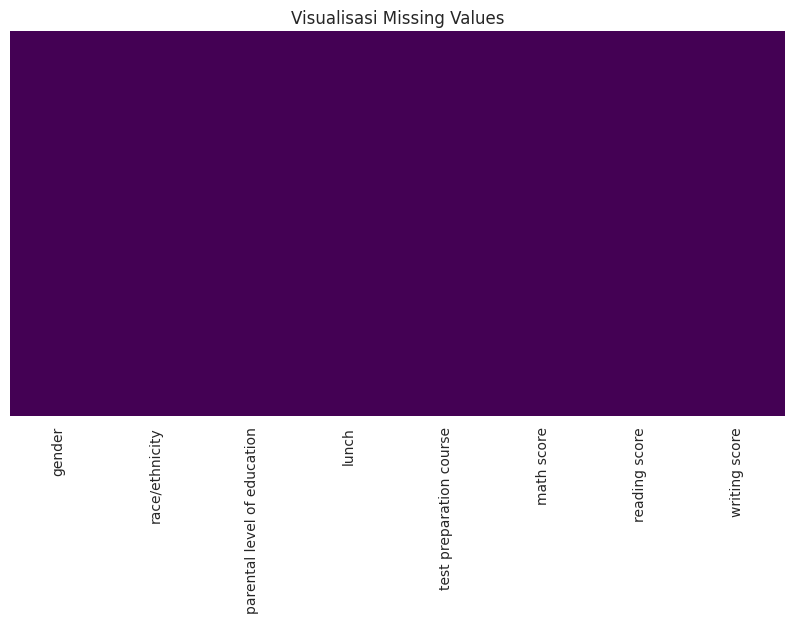

In [8]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis',
    yticklabels=False
)

plt.title('Visualisasi Missing Values')
plt.show()

Sel 7 — Memeriksa Data Duplikat

In [9]:
# Menghitung jumlah data duplikat
duplicate_count = df.duplicated().sum()

print("Jumlah data duplikat:", duplicate_count)

Jumlah data duplikat: 0


In [10]:
df = df.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:", len(df))

Jumlah data setelah menghapus duplikat: 1000


Sel 8 — Analisis Distribusi Data Kategorikal


Distribusi gender:
gender
female    518
male      482
Name: count, dtype: int64


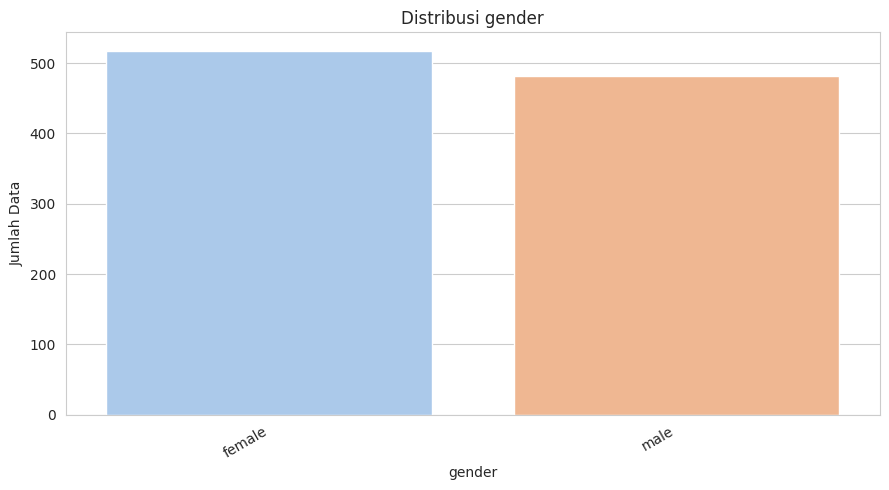


Distribusi race/ethnicity:
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64


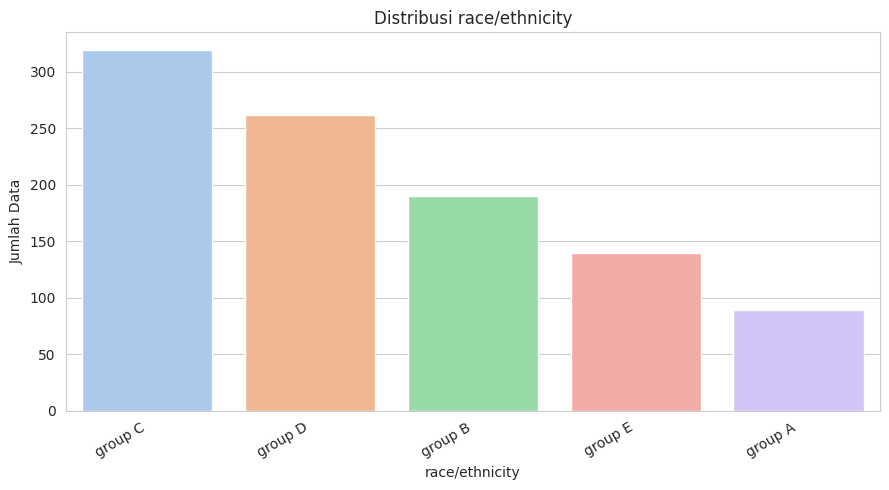


Distribusi parental level of education:
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


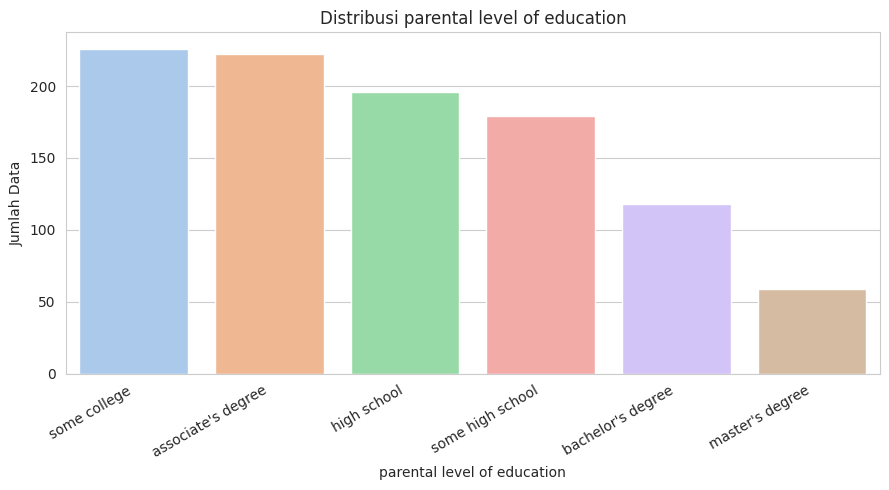


Distribusi lunch:
lunch
standard        645
free/reduced    355
Name: count, dtype: int64


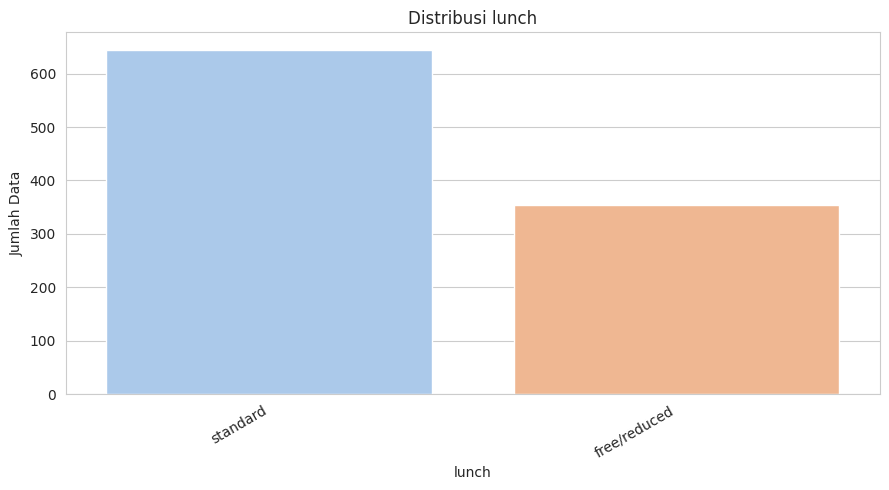


Distribusi test preparation course:
test preparation course
none         642
completed    358
Name: count, dtype: int64


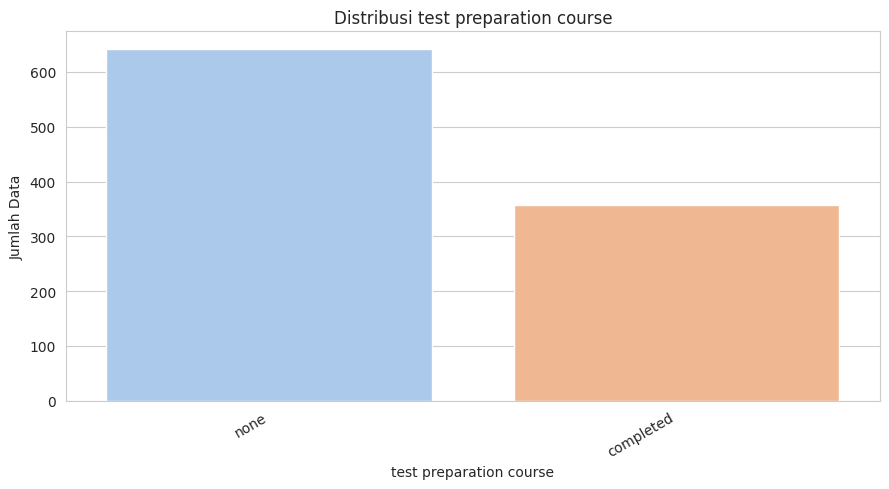

In [11]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

for column in categorical_columns:

    print(f"\nDistribusi {column}:")
    print(df[column].value_counts())

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index,
        palette='pastel'
    )

    plt.title(f'Distribusi {column}')
    plt.xlabel(column)
    plt.ylabel('Jumlah Data')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

Sel 9 — Analisis Distribusi Nilai Siswa

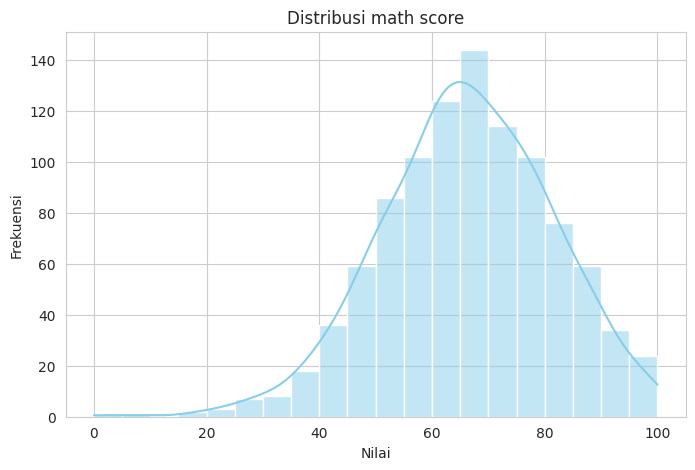

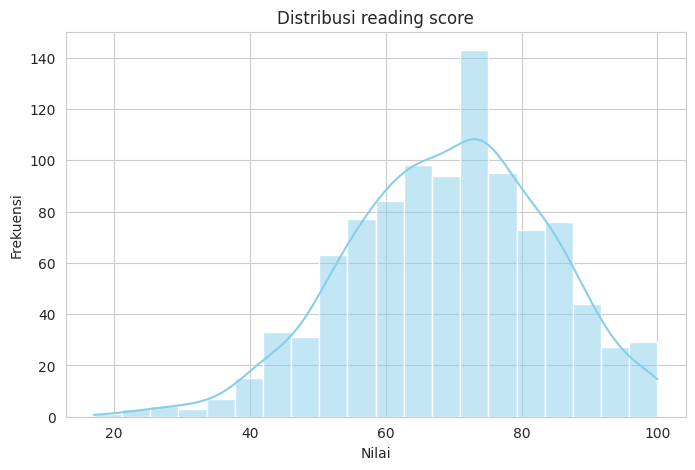

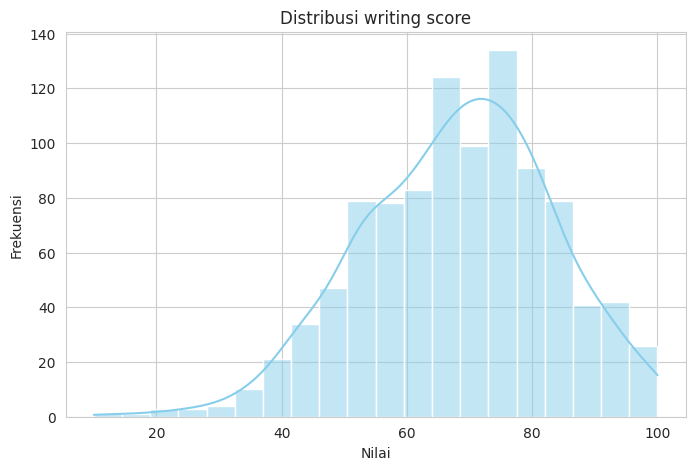

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = [
    'math score',
    'reading score',
    'writing score'
]

for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=20,
        color='skyblue'
    )

    plt.title(f'Distribusi {column}')
    plt.xlabel('Nilai')
    plt.ylabel('Frekuensi')

    plt.show()

Sel 10 — Analisis Boxplot

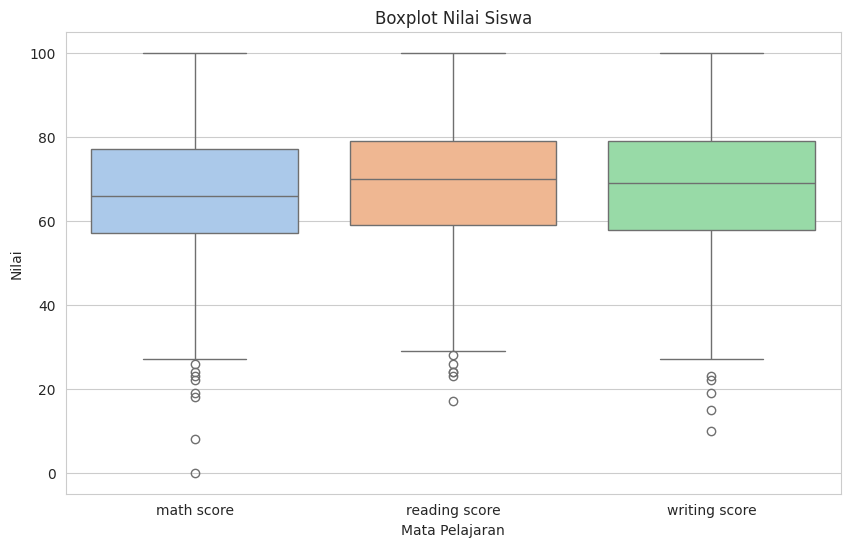

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[numerical_columns],
    palette='pastel'
)

plt.title('Boxplot Nilai Siswa')
plt.xlabel('Mata Pelajaran')
plt.ylabel('Nilai')

plt.show()

Sel 11 — Analisis Korelasi

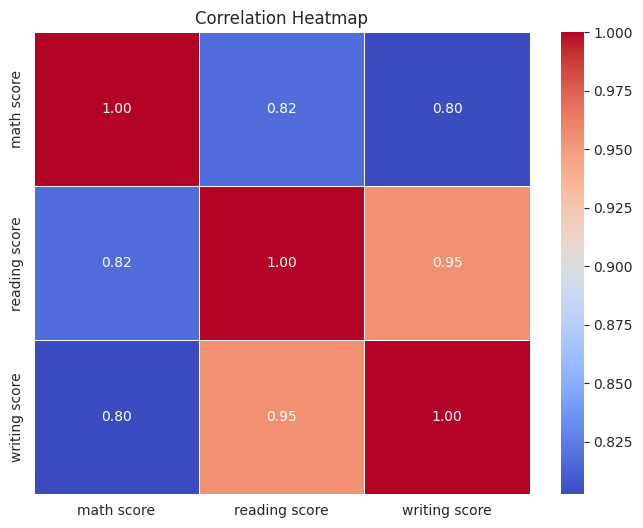

In [14]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

Sel 12 — Analisis Perbandingan Nilai Berdasarkan Gender

,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


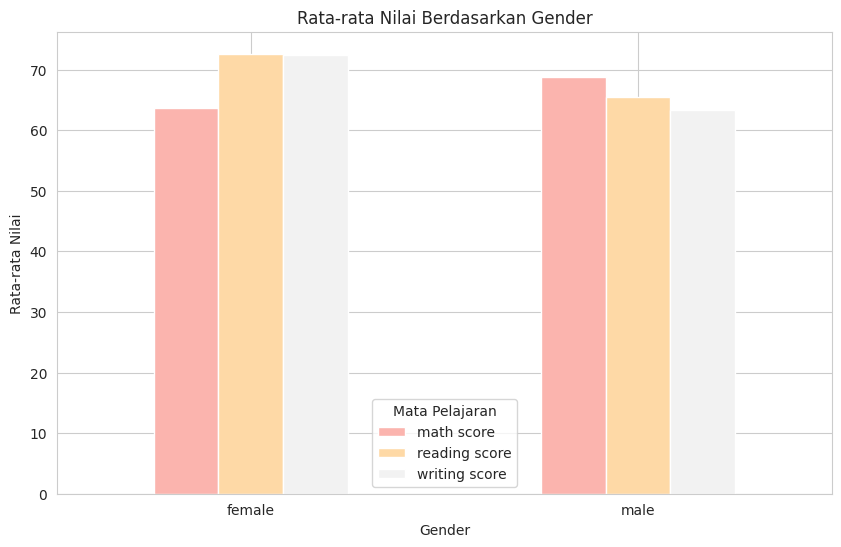

In [15]:
gender_score = df.groupby('gender')[
    numerical_columns
].mean()

display(gender_score)

gender_score.plot(
    kind='bar',
    figsize=(10, 6),
    colormap='Pastel1'
)

plt.title('Rata-rata Nilai Berdasarkan Gender')
plt.xlabel('Gender')
plt.ylabel('Rata-rata Nilai')
plt.xticks(rotation=0)
plt.legend(title='Mata Pelajaran')
plt.show()

Sel 13 — Analisis Nilai Berdasarkan Test Preparation Course

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


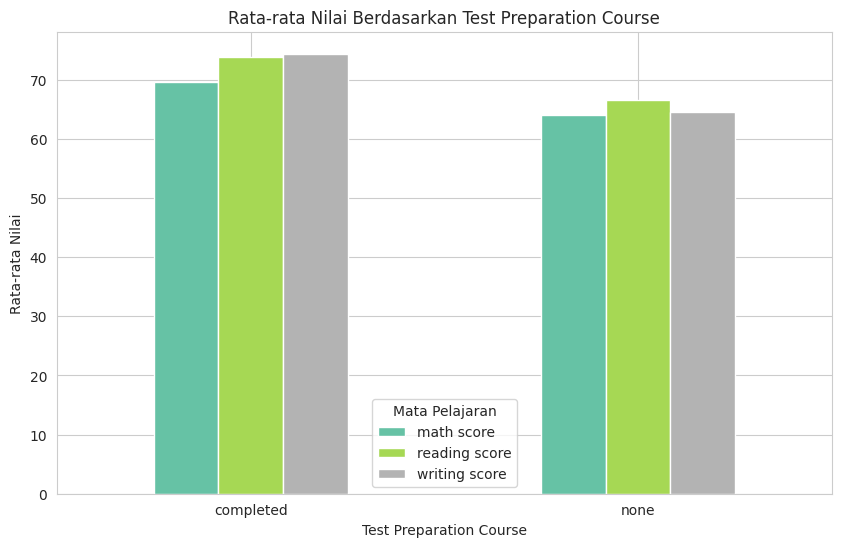

In [16]:
preparation_score = df.groupby(
    'test preparation course'
)[numerical_columns].mean()

display(preparation_score)

preparation_score.plot(
    kind='bar',
    figsize=(10, 6),
    colormap='Set2'
)

plt.title('Rata-rata Nilai Berdasarkan Test Preparation Course')
plt.xlabel('Test Preparation Course')
plt.ylabel('Rata-rata Nilai')
plt.xticks(rotation=0)
plt.legend(title='Mata Pelajaran')
plt.show()